### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score

### Data loading + appending with results from previous query

In [2]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [3]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (12, 2), y = (12,)
Function 2: X = (12, 2), y = (12,)
Function 3: X = (17, 3), y = (17,)
Function 4: X = (32, 4), y = (32,)
Function 5: X = (22, 4), y = (22,)
Function 6: X = (22, 5), y = (22,)
Function 7: X = (32, 6), y = (32,)
Function 8: X = (42, 8), y = (42,)


### Reusable functions

In [4]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [5]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [6]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [7]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [8]:
def plot_gp_2d(i, gp, suggestions=None):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean = gp.predict(X_grid)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    if suggestions:
        for name, point in suggestions.items():
            plt.scatter(*point, marker="X", s=120, label=name)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.legend()
    plt.show()

In [33]:
def plot_3d(i, suggestions=None):
    X, y = functions[i]["X"], functions[i]["y"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    p = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                   c=y, cmap="viridis", s=70)

    # Last week's query
    ax.scatter(*X[-1], marker="*", s=300,
               edgecolors="red", facecolors="none",
               linewidths=2, label="Last week's query")

    if suggestions:
        for name, point in suggestions.items():
            ax.scatter(*point, marker="X", s=150, label=name)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}")
    ax.legend()
    plt.colorbar(p, label="Output")
    plt.show()

In [45]:
def plot_3d_suggestions(i, suggestions):
    X = functions[i]["X"]
    y = functions[i]["y"]

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    # Existing observations
    p = ax.scatter(X[:,0], X[:,1], X[:,2], c=y, cmap="viridis", s=60)
    plt.colorbar(p, label="Output")

    # Acquisition suggestions
    markers = {"UCB": "^", "EI": "s", "PI": "X"}

    for name, point in suggestions.items():
        ax.scatter(
            point[0], point[1], point[2],
            marker=markers[name],
            s=180,
            label=name
        )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}: Acquisition Suggestions")
    ax.legend()

    plt.show()

In [9]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

In [10]:
def check_uncertainty(gp, suggestions):
    for name, point in suggestions.items():
        mean, std = gp.predict(point.reshape(1, -1), return_std=True)

        print(
            f"{name}: mean={mean[0]:.4f}, "
            f"uncertainty={std[0]:.4f}"
        )

In [11]:
def plot_scores(i):
    y = functions[i]["y"]
    positions = np.arange(len(y))
    best = np.argmax(y)

    plt.figure(figsize=(10, 5))
    plt.scatter(positions, y, s=70)

    # Label points with array position
    for pos, score in zip(positions, y):
        plt.annotate(str(pos), (pos, score),
                     xytext=(5, 5),
                     textcoords="offset points")

    # Last week's query
    plt.scatter(positions[-1], y[-1],
                marker="*", s=250,
                facecolors="none", edgecolors="red",
                linewidths=2, label="Last week's query")

    # Best observation
    plt.scatter(best, y[best],
                marker="X", s=200,
                label="Best score")

    plt.xlabel("Array position")
    plt.ylabel("Observed score")
    plt.title(f"Function {i}: Observed Scores")
    plt.legend()
    plt.show()

In [12]:
def uncertainty_search(gp, candidates, ranges):
    mean, std = gp.predict(candidates, return_std=True)

    for low, high in ranges:
        mask = (std >= low) & (std < high)

        if mask.any():
            idx = np.argmax(mean[mask])
            point = candidates[mask][idx]

            print(
                f"std {low:.2f}-{high:.2f}:",
                np.round(point, 3),
                f"mean={mean[mask][idx]:.3f}",
                f"std={std[mask][idx]:.3f}"
            )

In [78]:
def format_query(point):
    return "-".join(f"{v:.6f}" for v in point)

### Function 1

In [18]:
check_result(1)

Function 1
Latest: X=[0.728709 0.761212], y=-4.548861273606175e-20
Best:   X=[0.73102363 0.73299988], y=7.710875114502849e-16


using transformations to make sense of the data

In [19]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.63636364 0.81818182 1.         0.45454545 0.         0.27272727
 0.36363636 0.90909091 0.54545455 0.72727273 0.18181818 0.09090909]


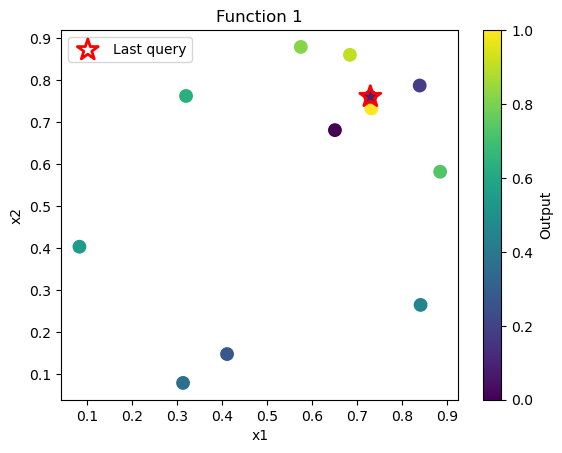

In [20]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

function 1 is very difficult to analyse - i think that making a huge manual exploration this week would at least give me some information about the empty unexplored space 

#### chosen query for F1

`0.400000-0.500000`

### Function 2

Function 2
Latest: X=[0.69 0.5 ], y=0.4690061148444333
Best:   X=[0.70263656 0.9265642 ], y=0.6112052157614438


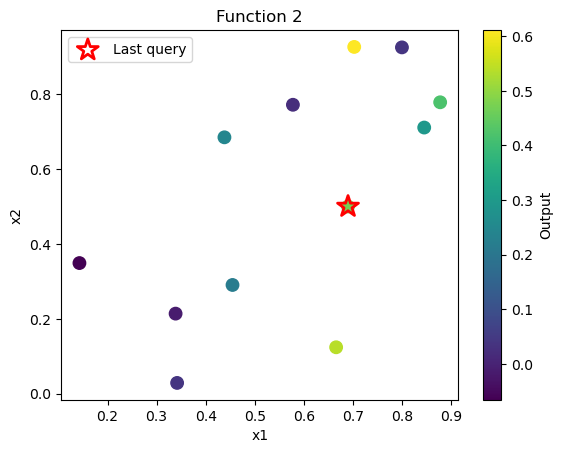

In [21]:
check_result(2)
plot_2d(2)

My initial hypothesis has a lot more evidence now - the region around `x1 = 0.69-0.71` is performing pretty well. 

I want to take a controlled manual balanced approach and hold x1 exactly at the best known value and move x2 closer towards the best.

#### chosen query for F2

`0.70263656, 0.85000000`

### Function 3

In [30]:
check_result(3)

Function 3
Latest: X=[0.181135 0.270895 0.418968], y=-0.027149095597068146
Best:   X=[0.181135 0.270895 0.418968], y=-0.027149095597068146


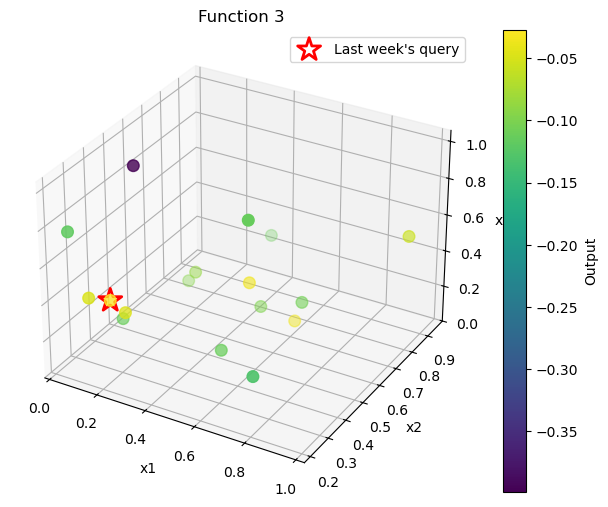

In [34]:
plot_3d(3)

For F3 last week:
- EI predicted mean: `-0.0654`
- Predicted uncertainty: `0.0683`
- Actual result: `-0.0271491`
- Previous best: `-0.0348353`

So the GP was pessimistic, it underestimated the performance by ~0.0383. 

In [35]:
validate_kernels(3)

[(('RBF', 0.1), np.float64(0.04134306572063539)),
 (('Matern', 0.1), np.float64(0.042193789813682166)),
 (('RQ', 0.1), np.float64(0.04323708573327298)),
 (('RQ', 0.05), np.float64(0.043529150141934814)),
 (('RBF', 0.05), np.float64(0.04473340489063163)),
 (('Matern', 0.05), np.float64(0.04500263632316583)),
 (('Matern', 0.2), np.float64(0.047649723962512075)),
 (('RBF', 0.2), np.float64(0.051595546438166495)),
 (('RQ', 0.2), np.float64(0.05240520428013201)),
 (('Matern', 0.5), np.float64(0.06100651788622812)),
 (('RQ', 0.5), np.float64(0.06101468698579929)),
 (('RBF', 0.5), np.float64(0.0702462547957531))]

1. The preferred length scale moved from 0.05 → 0.1.
The data now supports a slightly smoother / less extremely local relationship.
2. RBF has overtaken RQ.

In [41]:
best_kernel_f3 = RBF(length_scale=0.1)

gp_f3 = fit_gp(3, best_kernel_f3)

In [42]:
rng = np.random.RandomState(42)
X_candidates_f3 = rng.rand(10000, 3)

In [43]:
suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates_f3,
    best_y=functions[3]["y"].max()
)

suggestions_f3

{'UCB': array([0.28993709, 0.18668393, 0.40639985]),
 'EI': array([0.24166281, 0.20673531, 0.39685927]),
 'PI': array([0.21399468, 0.2832844 , 0.40031284])}

In [44]:
check_uncertainty(gp_f3, suggestions_f3)

UCB: mean=-0.0687, uncertainty=0.0738
EI: mean=-0.0472, uncertainty=0.0586
PI: mean=-0.0286, uncertainty=0.0153


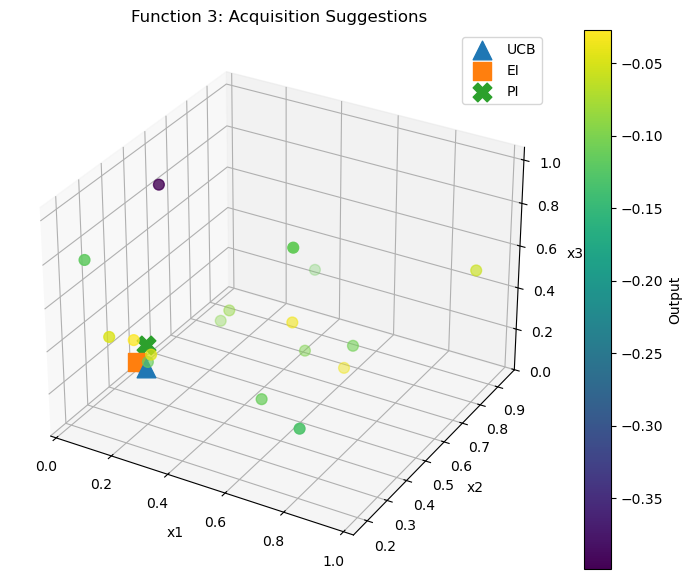

In [46]:
plot_3d_suggestions(3, suggestions_f3)

Since we made an improvement, I want to confirm whether I have actually found a promising region. I am leaning towards EI this round again since PI is essentially sitting on last week's query point.

If there no improvement, I will be more exploratory next week.

In [79]:
print(format_query(suggestions_f3["EI"]))

0.241663-0.206735-0.396859


#### chosen query for F3

`0.241663-0.206735-0.396859`

### Function 4

last week's query produced a new best however the GP was way too optimistic - it predicted `-2.28` but we actually got `-3.7` which is a prediction error of about -1.42 compared to its 0.28 uncertainty.

In [50]:
check_result(4)
validate_kernels(4)

Function 4
Latest: X=[0.59603  0.460386 0.36441  0.353005], y=-3.7019901507901447
Best:   X=[0.59603  0.460386 0.36441  0.353005], y=-3.7019901507901447


[(('RQ', 0.5), np.float64(1.792954694404137)),
 (('Matern', 0.5), np.float64(2.1601406104977183)),
 (('RBF', 0.5), np.float64(2.5162828222466818)),
 (('RQ', 0.2), np.float64(2.8818360276319375)),
 (('RBF', 0.2), np.float64(3.3393068866426727)),
 (('Matern', 0.2), np.float64(3.3870344951053033)),
 (('RQ', 0.1), np.float64(3.8251865509424876)),
 (('RBF', 0.1), np.float64(4.563210703568879)),
 (('Matern', 0.1), np.float64(4.704101382781843)),
 (('RQ', 0.05), np.float64(4.977403464384469)),
 (('Matern', 0.05), np.float64(5.802847001629991)),
 (('RBF', 0.05), np.float64(5.8397284953274315))]

In [51]:
best_kernel_f4 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f4 = fit_gp(4, best_kernel_f4)

In [52]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(20000, 4)

suggestions_f4 = acquisitions(
    gp_f4,
    X_candidates,
    best_y=functions[4]["y"].max(),
    beta=1.96
)

suggestions_f4

{'UCB': array([0.36823275, 0.4922238 , 0.41324419, 0.45577844]),
 'EI': array([0.48701649, 0.43876242, 0.40735702, 0.36501417]),
 'PI': array([0.48701649, 0.43876242, 0.40735702, 0.36501417])}

In [53]:
check_uncertainty(gp_f4, suggestions_f4)

UCB: mean=-3.6190, uncertainty=1.6716
EI: mean=-2.8923, uncertainty=0.8362
PI: mean=-2.8923, uncertainty=0.8362


although there was an issue with the GP being overly optimistic i think i still want to exploit the promising region just to confirm the area

In [77]:
print(format_query(suggestions_f4["EI"]))

0.487016-0.438762-0.407357-0.365014


Last week's query produced a new best, so continue refining that region. EI and PI independently selected the same point, which stays relatively close to the current best while primarily testing a decrease in x1.

Despite the caveat of the GP substantially overestimating last week's performance, I am choosing this more because of the location and acquisition agreement than because we believe the predicted value literally.

#### chosen query for F4

`0.487016-0.438762-0.407357-0.365014`

### Function 5

made a huge improvement to last week! so have found the promising region - now working on refinement

In [58]:
check_result(5)
validate_kernels(5)

Function 5
Latest: X=[0.205157 0.941657 0.905832 0.870015], y=1719.6836742607081
Best:   X=[0.205157 0.941657 0.905832 0.870015], y=1719.6836742607081


[(('Matern', 0.5), np.float64(96.52812877971309)),
 (('RQ', 0.2), np.float64(104.07462127582609)),
 (('RQ', 0.5), np.float64(106.04150066652569)),
 (('RBF', 0.5), np.float64(115.06168464559344)),
 (('Matern', 0.2), np.float64(144.196302641602)),
 (('RQ', 0.1), np.float64(155.2467741532192)),
 (('RBF', 0.2), np.float64(164.1187412577635)),
 (('RQ', 0.05), np.float64(207.2159266288975)),
 (('Matern', 0.1), np.float64(223.8596120851332)),
 (('RBF', 0.1), np.float64(227.31541051450085)),
 (('Matern', 0.05), np.float64(248.27580514321792)),
 (('RBF', 0.05), np.float64(249.20773218985994))]

In [59]:
best_kernel_f5 = Matern(length_scale=0.5, nu=2.5)

gp_f5 = fit_gp(5, best_kernel_f5)

In [62]:
best = functions[5]["X"][np.argmax(functions[5]["y"])]

rng = np.random.RandomState(42)
X_candidates_f5 = best + rng.uniform(-0.1, 0.1, (20000, 4)) # 0.1 to choose local search radius
X_candidates_f5 = np.clip(X_candidates_f5, 0, 1)

suggestions_f5 = acquisitions(
    gp_f5,
    X_candidates_f5,
    best_y=functions[5]["y"].max()
)

suggestions_f5

{'UCB': array([0.30262011, 1.        , 1.        , 0.96367466]),
 'EI': array([0.30262011, 1.        , 1.        , 0.96367466]),
 'PI': array([0.18006502, 1.        , 0.95223079, 0.8897467 ])}

In [63]:
check_uncertainty(gp_f5, suggestions_f5)

UCB: mean=2596.0207, uncertainty=119.5655
EI: mean=2596.0207, uncertainty=119.5655
PI: mean=2187.6987, uncertainty=54.5686


the GP is predicting really strong results - i can't trust them fully, so I am leaning towards the more conservative PI acquisition this time 

In [76]:
print(format_query(suggestions_f5["PI"]))

0.180065-1.000000-0.952231-0.889747


#### chosen query for F5

`0.180065-1.000000-0.952231-0.889747`

### Function 6

In [66]:
check_result(6)
validate_kernels(6)

Function 6
Latest: X=[0.38627  0.29408  0.486489 0.729857 0.047472], y=-0.33573744180095905
Best:   X=[0.38627  0.29408  0.486489 0.729857 0.047472], y=-0.33573744180095905


[(('RQ', 0.5), np.float64(0.21039666362317486)),
 (('RBF', 0.5), np.float64(0.22835804346238986)),
 (('Matern', 0.5), np.float64(0.2365796834919677)),
 (('RQ', 0.2), np.float64(0.28551246110412454)),
 (('Matern', 0.2), np.float64(0.34794459283587503)),
 (('RBF', 0.2), np.float64(0.35567088004577146)),
 (('RQ', 0.1), np.float64(0.3595597546083415)),
 (('RBF', 0.1), np.float64(0.4016595753686225)),
 (('RQ', 0.05), np.float64(0.4027251073573428)),
 (('Matern', 0.1), np.float64(0.4051681207040882)),
 (('Matern', 0.05), np.float64(0.42451885960374014)),
 (('RBF', 0.05), np.float64(0.4256999579785553))]

In [67]:
best_kernel_f6 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f6 = fit_gp(6, best_kernel_f6)

#### exploiting around the newly discovered region

In [72]:
best = functions[6]["X"][np.argmax(functions[6]["y"])]

rng = np.random.RandomState(42)
X_candidates_f6 = best + rng.uniform(-0.15, 0.15, (20000, 5)) # 0.15 - local but a bit more broad than 0.1 
X_candidates_f6 = np.clip(X_candidates_f6, 0, 1)

suggestions_f6 = acquisitions(
    gp_f6,
    X_candidates_f6,
    best_y=functions[6]["y"].max()
)

suggestions_f6

{'UCB': array([0.40564719, 0.34298816, 0.54020898, 0.85937912, 0.19655683]),
 'EI': array([0.45432986, 0.36386937, 0.50831534, 0.75716368, 0.15016692]),
 'PI': array([0.41269587, 0.3152869 , 0.48176886, 0.7448507 , 0.04500919])}

In [73]:
check_uncertainty(gp_f6, suggestions_f6)

UCB: mean=-0.4282, uncertainty=0.1651
EI: mean=-0.3494, uncertainty=0.1041
PI: mean=-0.3298, uncertainty=0.0269


EI chosen for moderate exploration - moved further from the current best than PI to seek a possible larger improvement, while avoiding the higher uncertainty of UCB.

In [75]:
print(format_query(suggestions_f6["EI"]))

0.454330-0.363869-0.508315-0.757164-0.150167


#### chosen query for F6

`0.454330-0.363869-0.508315-0.757164-0.150167`

### Function 7

In [81]:
check_result(7)
validate_kernels(7)

Function 7
Latest: X=[0.084386 0.47044  0.257085 0.235966 0.461692 0.651149], y=1.3229747673311643
Best:   X=[0.05789554 0.49167222 0.24742222 0.21811844 0.42042833 0.73096984], y=1.3649683044991994


[(('RQ', 0.2), np.float64(0.16380469918449048)),
 (('Matern', 0.5), np.float64(0.16659288960892066)),
 (('RQ', 0.5), np.float64(0.1707286273995403)),
 (('Matern', 0.2), np.float64(0.19246270234605664)),
 (('RBF', 0.2), np.float64(0.19434283130760877)),
 (('RQ', 0.1), np.float64(0.20047183666747254)),
 (('RBF', 0.1), np.float64(0.22343121798793367)),
 (('Matern', 0.1), np.float64(0.23025430815731782)),
 (('RQ', 0.05), np.float64(0.2431683648055324)),
 (('RBF', 0.05), np.float64(0.26586824484101146)),
 (('RBF', 0.5), np.float64(0.2686015435352713)),
 (('Matern', 0.05), np.float64(0.2699418651125117))]

In [84]:
best_kernel_f7 = RationalQuadratic(
    length_scale=0.2,
    alpha=1.0
)

gp_f7 = fit_gp(7, best_kernel_f7)

#### searching for unexplored region near the best 

In [90]:
from scipy.spatial.distance import cdist

best = functions[7]["X"][np.argmax(functions[7]["y"])]

rng = np.random.RandomState(42)
candidates = rng.uniform(0, 1, (50000, 6))

# Distance from current best
dist_best = np.linalg.norm(candidates - best, axis=1)

# staying around the best, but not getting too close
mask = (dist_best >= 0.15) & (dist_best <= 0.35)
local_candidates = candidates[mask]

mean, std = gp_f7.predict(local_candidates, return_std=True)
ucb = mean + 1.96 * std

idx = np.argmax(ucb)
query_f7 = local_candidates[idx]

print("Query:", query_f7)
print("Distance from best:", np.linalg.norm(query_f7 - best))
print("Predicted mean:", mean[idx])
print("Uncertainty:", std[idx])
print("UCB:", ucb[idx])

Query: [0.14398031 0.44121541 0.20786913 0.135499   0.34863856 0.73427422]
Distance from best: 0.15333487800847886
Predicted mean: 1.0920745164584593
Uncertainty: 0.24358922693367904
UCB: 1.5695094012484703


Used UCB to explore around the known best region while enforcing a minimum distance from the current best. This avoids another very small local adjustment while retaining evidence from the strongest-performing region.

In [91]:
print(format_query(query_f7))

0.143980-0.441215-0.207869-0.135499-0.348639-0.734274


#### chosen query for F7

`0.143980-0.441215-0.207869-0.135499-0.348639-0.734274`

### Function 8

In [93]:
check_result(8)
validate_kernels(8)

Function 8
Latest: X=[0.047619 0.080988 0.047004 0.073288 0.406415 0.769833 0.477669 0.861352], y=9.6519050086281
Best:   X=[0.047619 0.080988 0.047004 0.073288 0.406415 0.769833 0.477669 0.861352], y=9.6519050086281


[(('RQ', 0.5), np.float64(0.36038406513317267)),
 (('RBF', 0.5), np.float64(0.41042708098165565)),
 (('Matern', 0.5), np.float64(0.4325944283634503)),
 (('RQ', 0.2), np.float64(0.5741983194982535)),
 (('RQ', 0.1), np.float64(0.695553976204956)),
 (('Matern', 0.2), np.float64(0.7051558686298928)),
 (('RBF', 0.2), np.float64(0.7092716682058011)),
 (('RBF', 0.1), np.float64(0.7536591777134278)),
 (('Matern', 0.1), np.float64(0.7612481829051928)),
 (('RQ', 0.05), np.float64(0.7686858255436133)),
 (('RBF', 0.05), np.float64(0.801098558619715)),
 (('Matern', 0.05), np.float64(0.8056608851647188))]

In [94]:
best_kernel_f8 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f8 = fit_gp(8, best_kernel_f8)

In [95]:
best = functions[8]["X"][np.argmax(functions[8]["y"])]

rng = np.random.RandomState(42)
X_candidates_f8 = best + rng.uniform(-0.1, 0.1, (50000, 8))
X_candidates_f8 = np.clip(X_candidates_f8, 0, 1)

suggestions_f8 = acquisitions(
    gp_f8,
    X_candidates_f8,
    best_y=functions[8]["y"].max()
)

suggestions_f8

{'UCB': array([0.1442027 , 0.17126201, 0.        , 0.16086552, 0.48736017,
        0.6941397 , 0.40447278, 0.76849169]),
 'EI': array([0.1442027 , 0.17126201, 0.        , 0.16086552, 0.48736017,
        0.6941397 , 0.40447278, 0.76849169]),
 'PI': array([0.06141268, 0.10834974, 0.09461727, 0.14341531, 0.38904778,
        0.70476247, 0.42331699, 0.79446521])}

In [96]:
check_uncertainty(gp_f8, suggestions_f8)

UCB: mean=9.7419, uncertainty=0.3373
EI: mean=9.7419, uncertainty=0.3373
PI: mean=9.7370, uncertainty=0.1306


In [97]:
print(format_query(suggestions_f8["EI"]))

0.144203-0.171262-0.000000-0.160866-0.487360-0.694140-0.404473-0.768492


Local exploration using UCB/EI after last week's successful PI exploitation. Both gave the same point with a predicted mean of 9.74 but greater uncertainty, allowing more exploration within the promising region.

#### final query choice for F8

`0.144203-0.171262-0.000000-0.160866-0.487360-0.694140-0.404473-0.768492`